# EAPS 507 — Pandas for Earth Science Data Manipulation
## A 2-hour guided in-class tutorial using Indiana geographic features

**Dataset:** `IN_Features_20140204.txt`

### Learning objectives
By the end of this activity, you should be able to:

1. load a non-comma-delimited text file with `pandas`;
2. inspect a `DataFrame` and diagnose its structure;
3. select columns and filter observations with Boolean conditions;
4. identify and handle missing values deliberately;
5. summarize categorical and numerical data;
6. use `groupby()` and `agg()` to answer scientific questions;
7. sort data and create derived variables;
8. convert text dates into datetime objects; and
9. combine several Pandas operations to answer a question you formulate yourself.

### How this notebook works
This is **not** a copy-and-paste exercise. Each section follows the same cycle:

> **Explain → instructor example → predict/test → your turn → interpret**

Some cells are complete. Others contain blanks (`...`) for you to complete. Before running a **Predict first** cell, write down what you expect to happen.

**Suggested pace:** Sections 1–3 (45 min), Sections 4–6 (45 min), Sections 7–8 + final challenge (30 min).

### Completed tutorial notes
The short answer cells below explain the steps and results. Put `IN_Features_20140204.txt` in the same folder as this notebook and use **Restart Kernel and Run All** to reproduce the output. The full file has 29,536 records; questions asking for Indiana use the 29,417 records with `STATE_ALPHA == "IN"`.

## 0. Setup and the dataset — about 5 minutes

The file contains named geographic features and attributes such as feature class, state, county, latitude/longitude, elevation, map name, and dates. It is a **pipe-delimited** text file, so fields are separated by `|` rather than commas.

The goal today is not to memorize Pandas syntax. The goal is to learn how to move from a **data question** to an appropriate sequence of Pandas operations.

In [1]:
import pandas as pd

# This option makes wide tables easier to inspect in Jupyter.
pd.set_option("display.max_columns", 25)

In [2]:
# read_csv() can read many delimited text files, not only .csv files.
# sep="|" tells Pandas that the vertical bar separates the columns.

df = pd.read_csv("IN_Features_20140204.txt", sep="|")

df.head()

,FEATURE_ID,FEATURE_NAME,FEATURE_CLASS,STATE_ALPHA,STATE_NUMERIC,COUNTY_NAME,COUNTY_NUMERIC,PRIMARY_LAT_DMS,PRIM_LONG_DMS,PRIM_LAT_DEC,PRIM_LONG_DEC,SOURCE_LAT_DMS,SOURCE_LONG_DMS,SOURCE_LAT_DEC,SOURCE_LONG_DEC,ELEV_IN_M,ELEV_IN_FT,MAP_NAME,DATE_CREATED,DATE_EDITED
0,403294,Brouilletts Creek,Stream,IN,18,Whitley,183,393617N,0872305W,39.604762,-87.384782,393919N,0874800W,39.655230,-87.799900,144.0,472.0,New Goshen,01/15/1980,11/19/2010
1,404056,Beaver Creek,Stream,IL,17,Iroquois,75,405811N,0874850W,40.969755,-87.813927,410159N,0872342W,41.033090,-87.395030,186.0,610.0,L'Erable,01/15/1980,NaN
2,406202,Clear Creek,Stream,IL,17,Edgar,45,392645N,0873001W,39.445869,-87.500300,393514N,0874118W,39.587257,-87.688360,146.0,479.0,Dennison,01/15/1980,NaN
3,406288,Coal Creek,Stream,IL,17,Edgar,45,393829N,0873006W,39.641425,-87.501687,393855N,0873750W,39.648646,-87.630580,151.0,495.0,Saint Bernice,01/15/1980,NaN
4,406345,Cole Creek,Stream,IL,17,Iroquois,75,403756N,0873331W,40.632259,-87.558636,403756N,0873331W,40.632259,-87.558636,207.0,679.0,Darrow,01/15/1980,NaN


### Student-led test 0
Without running another command yet, inspect the first five rows above.

1. Name **two categorical** variables.
2. Name **two numerical** variables.
3. Identify one variable that appears to contain missing values.
4. Why would `pd.read_csv(..., sep="|")` work even though the filename ends in `.txt`?

Discuss your answers with a neighbor for 2 minutes.

**My notes:**
1. `FEATURE_CLASS` and `COUNTY_NAME` are categorical variables.
2. `PRIM_LAT_DEC` and `ELEV_IN_M` are numerical measurements.
3. `DATE_EDITED` has missing values in the first five rows.
4. `read_csv()` uses the separator we give it. The `.txt` extension does not stop it from reading a table separated by `|`.

`FEATURE_ID` is a number, but it is an identifier, so averaging it would not tell me anything useful.

---
## 1. Inspecting a DataFrame — about 15 minutes

Before manipulating a dataset, learn its structure.

Useful attributes/methods:

- `df.head()` — first rows
- `df.tail()` — last rows
- `df.shape` — `(number of rows, number of columns)`
- `df.columns` — column labels
- `df.dtypes` — inferred data type of each column
- `df.info()` — compact summary including non-null counts and data types

Notice that `shape`, `columns`, and `dtypes` are **attributes**, while `head()` and `info()` are **methods**.

In [3]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Shape: (29536, 20)

Column names:
['FEATURE_ID', 'FEATURE_NAME', 'FEATURE_CLASS', 'STATE_ALPHA', 'STATE_NUMERIC', 'COUNTY_NAME', 'COUNTY_NUMERIC', 'PRIMARY_LAT_DMS', 'PRIM_LONG_DMS', 'PRIM_LAT_DEC', 'PRIM_LONG_DEC', 'SOURCE_LAT_DMS', 'SOURCE_LONG_DMS', 'SOURCE_LAT_DEC', 'SOURCE_LONG_DEC', 'ELEV_IN_M', 'ELEV_IN_FT', 'MAP_NAME', 'DATE_CREATED', 'DATE_EDITED']


### Predict first
What do you expect Pandas to report for `ELEV_IN_M`, `FEATURE_NAME`, and `DATE_CREATED`?

Write your prediction before running the next cell.

**Prediction:** I expect elevation to be numeric, while feature names and creation dates will start as text. Elevation might be a float if some entries are missing; dates need an explicit conversion.

In [4]:
df[["ELEV_IN_M", "FEATURE_NAME", "DATE_CREATED"]].dtypes

ELEV_IN_M       float64
FEATURE_NAME        str
DATE_CREATED        str
dtype: object

**After checking:** Elevation is `float64`. The name and date columns are `str`, so the dates are still text.

### Why is `DATE_CREATED` not automatically a date?
Pandas reads many text fields as `object` unless we explicitly tell it how to interpret them. Later, we will convert the date columns.

### Student-led test 1
Complete the cells below. Do not ask the instructor for the answer until you have tried the documentation/help system or discussed it with a neighbor.

In [5]:
# tail(7) selects the last seven records without changing their order.
df.tail(7)

,FEATURE_ID,FEATURE_NAME,FEATURE_CLASS,STATE_ALPHA,STATE_NUMERIC,COUNTY_NAME,COUNTY_NUMERIC,PRIMARY_LAT_DMS,PRIM_LONG_DMS,PRIM_LAT_DEC,PRIM_LONG_DEC,SOURCE_LAT_DMS,SOURCE_LONG_DMS,SOURCE_LAT_DEC,SOURCE_LONG_DEC,ELEV_IN_M,ELEV_IN_FT,MAP_NAME,DATE_CREATED,DATE_EDITED
29529,2743558,Upland Community Church,Church,IN,18,Grant,53,402756N,0853000W,40.465491,-85.499956,NaN,NaN,NaN,NaN,282.0,925.0,Hartford City West,12/26/2012,NaN
29530,2743605,John T. Myers Lock and Dam,Dam,KY,21,Union,225,374734N,0875929W,37.792778,-87.991390,NaN,NaN,NaN,NaN,99.0,325.0,Uniontown,12/28/2012,09/18/2013
29531,2745826,Kessinger Cemetery,Cemetery,IN,18,Henry,65,395757N,0851504W,39.965938,-85.251160,NaN,NaN,NaN,NaN,341.0,1119.0,New Castle East,03/10/2013,NaN
29532,2748942,Rising Hope Baptist Church,Church,IN,18,Brown,13,391223N,0861329W,39.206422,-86.224714,NaN,NaN,NaN,NaN,213.0,699.0,Nashville,07/16/2013,NaN
29533,2749894,Columbus City Cemetery,Cemetery,IN,18,Bartholomew,5,391256N,0855458W,39.215610,-85.916000,NaN,NaN,NaN,NaN,192.0,630.0,Columbus,09/03/2013,NaN
29534,2760566,Meadows Glen,Populated Place,IN,18,Hamilton,57,400407N,0855913W,40.068638,-85.986989,NaN,NaN,NaN,NaN,241.0,791.0,Riverwood,01/29/2014,NaN
29535,2760567,Meadows Knoll,Populated Place,IN,18,Hamilton,57,400416N,0855850W,40.070979,-85.980434,NaN,NaN,NaN,NaN,242.0,794.0,Riverwood,01/29/2014,NaN


In [6]:
# info() shows the data types and the number of non-missing values.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29536 entries, 0 to 29535
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   FEATURE_ID       29536 non-null  int64  
 1   FEATURE_NAME     29536 non-null  str    
 2   FEATURE_CLASS    29536 non-null  str    
 3   STATE_ALPHA      29536 non-null  str    
 4   STATE_NUMERIC    29536 non-null  int64  
 5   COUNTY_NAME      29536 non-null  str    
 6   COUNTY_NUMERIC   29536 non-null  int64  
 7   PRIMARY_LAT_DMS  29536 non-null  str    
 8   PRIM_LONG_DMS    29536 non-null  str    
 9   PRIM_LAT_DEC     29536 non-null  float64
 10  PRIM_LONG_DEC    29536 non-null  float64
 11  SOURCE_LAT_DMS   3838 non-null   str    
 12  SOURCE_LONG_DMS  3838 non-null   str    
 13  SOURCE_LAT_DEC   3838 non-null   float64
 14  SOURCE_LONG_DEC  3838 non-null   float64
 15  ELEV_IN_M        29498 non-null  float64
 16  ELEV_IN_FT       29498 non-null  float64
 17  MAP_NAME         29536 

**Interpretation:** Which columns immediately look like they may require special handling? Why?

**My interpretation:** Source coordinates and `DATE_EDITED` have lots of missing values. Elevation is missing in 38 rows, and the date columns need to be converted from text. I also need to filter by state for the Indiana questions.

---
## 2. Selecting columns and rows — about 15 minutes

A DataFrame is two-dimensional. We often need only part of it.

### Selecting one column
`df["COLUMN"]` returns a Pandas `Series`.

### Selecting several columns
Pass a **list of column names**: `df[["A", "B"]]`.

### `.loc[]`
`.loc[rows, columns]` is a flexible label-based selector.

In [7]:
# One column -> Series
feature_names = df["FEATURE_NAME"]
print(type(feature_names))
feature_names.head()

<class 'pandas.Series'>


0    Brouilletts Creek
1         Beaver Creek
2          Clear Creek
3           Coal Creek
4           Cole Creek
Name: FEATURE_NAME, dtype: str

In [8]:
# Several columns -> DataFrame
location = df[["FEATURE_NAME", "COUNTY_NAME", "PRIM_LAT_DEC", "PRIM_LONG_DEC"]]
location.head()

,FEATURE_NAME,COUNTY_NAME,PRIM_LAT_DEC,PRIM_LONG_DEC
0,Brouilletts Creek,Whitley,39.604762,-87.384782
1,Beaver Creek,Iroquois,40.969755,-87.813927
2,Clear Creek,Edgar,39.445869,-87.500300
3,Coal Creek,Edgar,39.641425,-87.501687
4,Cole Creek,Iroquois,40.632259,-87.558636


In [9]:
# .loc[row selection, column selection]
# Here ':' means all rows.
df.loc[:, ["FEATURE_NAME", "FEATURE_CLASS", "ELEV_IN_M"]].head()

,FEATURE_NAME,FEATURE_CLASS,ELEV_IN_M
0,Brouilletts Creek,Stream,144.0
1,Beaver Creek,Stream,186.0
2,Clear Creek,Stream,146.0
3,Coal Creek,Stream,151.0
4,Cole Creek,Stream,207.0


### Student-led test 2
Create a DataFrame named `geo` containing only:

`FEATURE_NAME`, `FEATURE_CLASS`, `COUNTY_NAME`, `PRIM_LAT_DEC`, `PRIM_LONG_DEC`, and `ELEV_IN_M`.

Then display rows 10 through 15 using `.loc[]`.

**Test yourself:** Is the end label included when using `.loc[10:15]`? Determine this from your output rather than guessing.

In [10]:
# Keep just the six variables needed for the geographic subset.
columns_needed = [
    "FEATURE_NAME", "FEATURE_CLASS", "COUNTY_NAME",
    "PRIM_LAT_DEC", "PRIM_LONG_DEC", "ELEV_IN_M"
]
geo = df[columns_needed]

# loc uses index labels and includes both endpoints.
geo.loc[10:15]

,FEATURE_NAME,FEATURE_CLASS,COUNTY_NAME,PRIM_LAT_DEC,PRIM_LONG_DEC,ELEV_IN_M
10,Grand Calumet River,Stream,Cook,41.643924,-87.560878,177.0
11,Hawks Creek,Stream,Clark,39.383648,-87.516689,136.0
12,Hooper Branch,Stream,Iroquois,40.966700,-87.602811,192.0
13,Iroquois River,Stream,Kankakee,41.074199,-87.816429,181.0
14,Jonathan Creek,Stream,Edgar,39.866981,-87.500018,173.0
15,Jordan Creek,Stream,Vermilion,40.336148,-87.623077,197.0


**My check:** The output includes labels 10, 11, 12, 13, 14, and 15: six rows. The stop label is included with `.loc[]`; `.iloc[10:15]` would stop before position 15.

---
## 3. Boolean filtering — about 20 minutes

Filtering asks Pandas to keep only rows satisfying a condition.

For example, `df["FEATURE_CLASS"] == "Stream"` does **not** immediately return streams. It first produces a Boolean Series of `True` and `False` values. That Boolean mask can then be used to select rows.

In [11]:
is_stream = df["FEATURE_CLASS"] == "Stream"
is_stream.head(10)

0     True
1     True
2     True
3     True
4     True
5    False
6     True
7     True
8     True
9     True
Name: FEATURE_CLASS, dtype: bool

In [12]:
streams = df[is_stream]
streams[["FEATURE_NAME", "COUNTY_NAME", "ELEV_IN_M"]].head()

,FEATURE_NAME,COUNTY_NAME,ELEV_IN_M
0,Brouilletts Creek,Whitley,144.0
1,Beaver Creek,Iroquois,186.0
2,Clear Creek,Edgar,146.0
3,Coal Creek,Edgar,151.0
4,Cole Creek,Iroquois,207.0


### Predict first
What will the expression below return: a number, a Series, or a DataFrame?

```python
(df["ELEV_IN_M"] > 300)
```

Make your prediction, then test it.

**Prediction:** This should return a Boolean Series with one True/False value for each row, rather than a count or a filtered DataFrame.

In [13]:
df["ELEV_IN_M"] > 300

0        False
1        False
2        False
3        False
4        False
         ...  
29531     True
29532    False
29533    False
29534    False
29535    False
Name: ELEV_IN_M, Length: 29536, dtype: bool

**My check:** The result is a Boolean Series. To get the actual rows, I would put this mask inside `df[...]`. Missing elevation values do not pass the `> 300` condition.

### Combining conditions
Use:

- `&` for AND
- `|` for OR
- `~` for NOT
- `.isin([...])` when matching several allowed values

Put each condition in parentheses.

In [14]:
# Indiana streams above 250 m
high_in_streams = df[
    (df["STATE_ALPHA"] == "IN") &
    (df["FEATURE_CLASS"] == "Stream") &
    (df["ELEV_IN_M"] > 250)
]

high_in_streams[["FEATURE_NAME", "COUNTY_NAME", "ELEV_IN_M"]].head()

,FEATURE_NAME,COUNTY_NAME,ELEV_IN_M
131,Alexandria Creek,Madison,258.0
202,Amity Branch,Hancock,253.0
210,Ams Run,Hamilton,253.0
237,Andy Run,Madison,263.0
255,Anthony Creek,Hancock,283.0


In [15]:
# isin() is cleaner than writing many OR statements.
water_features = df[df["FEATURE_CLASS"].isin(["Stream", "Lake", "Reservoir", "Canal"])]
water_features.head()

,FEATURE_ID,FEATURE_NAME,FEATURE_CLASS,STATE_ALPHA,STATE_NUMERIC,COUNTY_NAME,COUNTY_NUMERIC,PRIMARY_LAT_DMS,PRIM_LONG_DMS,PRIM_LAT_DEC,PRIM_LONG_DEC,SOURCE_LAT_DMS,SOURCE_LONG_DMS,SOURCE_LAT_DEC,SOURCE_LONG_DEC,ELEV_IN_M,ELEV_IN_FT,MAP_NAME,DATE_CREATED,DATE_EDITED
0,403294,Brouilletts Creek,Stream,IN,18,Whitley,183,393617N,0872305W,39.604762,-87.384782,393919N,0874800W,39.655230,-87.799900,144.0,472.0,New Goshen,01/15/1980,11/19/2010
1,404056,Beaver Creek,Stream,IL,17,Iroquois,75,405811N,0874850W,40.969755,-87.813927,410159N,0872342W,41.033090,-87.395030,186.0,610.0,L'Erable,01/15/1980,NaN
2,406202,Clear Creek,Stream,IL,17,Edgar,45,392645N,0873001W,39.445869,-87.500300,393514N,0874118W,39.587257,-87.688360,146.0,479.0,Dennison,01/15/1980,NaN
3,406288,Coal Creek,Stream,IL,17,Edgar,45,393829N,0873006W,39.641425,-87.501687,393855N,0873750W,39.648646,-87.630580,151.0,495.0,Saint Bernice,01/15/1980,NaN
4,406345,Cole Creek,Stream,IL,17,Iroquois,75,403756N,0873331W,40.632259,-87.558636,403756N,0873331W,40.632259,-87.558636,207.0,679.0,Darrow,01/15/1980,NaN


### Student-led test 3A — basic filtering
Create `lakes` containing only records whose `FEATURE_CLASS` is `"Lake"`.

Then determine how many rows it contains. **Do not use a number supplied by the instructor. Let the data answer the question.**

In [16]:
# First select lake records, then count the rows in that subset.
lakes = df[df["FEATURE_CLASS"] == "Lake"]
print("Number of lake records (all states):", len(lakes))

Number of lake records (all states): 803


**Result:** There are 803 lake records in the whole file. This test does not ask for an Indiana-only filter; the Indiana-only total used later is 794.

### Student-led test 3B — combine conditions
Find all records that:

1. are in Indiana,
2. are either `Lake` or `Reservoir`, and
3. have elevation greater than 250 m.

Store the result as `high_water`. Display only feature name, class, county, and elevation.

In [17]:
# All three conditions must be true. isin() handles the two allowed classes.
high_water = df[
    (df["STATE_ALPHA"] == "IN") &
    (df["FEATURE_CLASS"].isin(["Lake", "Reservoir"])) &
    (df["ELEV_IN_M"] > 250)
]
print("Matching records:", len(high_water))
high_water[["FEATURE_NAME", "FEATURE_CLASS", "COUNTY_NAME", "ELEV_IN_M"]]

Matching records: 605


,FEATURE_NAME,FEATURE_CLASS,COUNTY_NAME,ELEV_IN_M
76,Adams Lake,Lake,LaGrange,289.0
154,Allen Lake,Lake,Kosciusko,266.0
246,Lake Anne,Lake,Steuben,316.0
290,Appleman Lake,Lake,LaGrange,295.0
396,Atwood Lake,Lake,LaGrange,273.0
...,...,...,...,...
24069,Clouse Lake,Lake,Noble,273.0
24190,Bell Lake,Lake,Johnson,251.0
25455,Lake Ullswater,Reservoir,Hamilton,273.0
25456,Lake Windemere,Reservoir,Hamilton,273.0


**Result:** There are 605 Indiana lake or reservoir records above 250 m. Each row has to satisfy the state, class, and elevation conditions at the same time.

### Check your reasoning
Explain why this expression can be dangerous:

```python
df["FEATURE_CLASS"] == "Lake" | df["FEATURE_CLASS"] == "Reservoir"
```

What role do parentheses play when combining Pandas Boolean conditions?

**My explanation:** Without parentheses, Python applies the operators in the wrong order for what I want. I would write `(df["FEATURE_CLASS"] == "Lake") | (df["FEATURE_CLASS"] == "Reservoir")`. The parentheses keep the two comparisons separate before combining them with OR.

---
## 4. Missing data — about 15 minutes

Real Earth-science datasets are rarely complete.

Useful tools:

- `.isna()` — identify missing values
- `.notna()` — identify non-missing values
- `.isna().sum()` — count missing values by column
- `.dropna()` — remove observations with missing values
- `.fillna()` — replace missing values

**Important:** missing-data treatment should follow the scientific question. Do not automatically drop every row containing any missing value.

In [18]:
missing = df.isna().sum()
missing.sort_values(ascending=False)

SOURCE_LONG_DMS    25698
SOURCE_LAT_DEC     25698
SOURCE_LONG_DEC    25698
SOURCE_LAT_DMS     25698
DATE_EDITED        23299
ELEV_IN_M             38
ELEV_IN_FT            38
FEATURE_ID             0
STATE_ALPHA            0
FEATURE_CLASS          0
FEATURE_NAME           0
STATE_NUMERIC          0
PRIM_LONG_DEC          0
PRIM_LAT_DEC           0
PRIM_LONG_DMS          0
PRIMARY_LAT_DMS        0
COUNTY_NAME            0
COUNTY_NUMERIC         0
MAP_NAME               0
DATE_CREATED           0
dtype: int64

### Predict first
Consider:

```python
df.dropna()
```

Would you expect this to retain most of the dataset or remove a large fraction? Use the missing-value summary above to justify your prediction **before** running it.

**Prediction:** I expect `dropna()` to remove a large fraction. Source coordinates are missing in 25,698 rows, and the edited date is missing in 23,299 rows, so requiring every field to be present is very restrictive.

In [19]:
# Now test the prediction.
print("Original rows:", len(df))
print("Rows after dropna() on ALL columns:", len(df.dropna()))

Original rows: 29536
Rows after dropna() on ALL columns: 125


In [20]:
# A targeted approach: require elevation only.
elevation_data = df.dropna(subset=["ELEV_IN_M"])

print("Original rows:", len(df))
print("Rows with elevation:", len(elevation_data))
print("Rows removed:", len(df) - len(elevation_data))

Original rows: 29536
Rows with elevation: 29498
Rows removed: 38


**My check:** Plain `dropna()` keeps only 125 of 29,536 rows. Requiring only elevation keeps 29,498 rows and removes 38. For an elevation question, the targeted version makes more sense because an absent edited date is not a reason to discard a usable elevation.

### Student-led test 4
Calculate the **percentage** of records with missing source latitude (`SOURCE_LAT_DEC`).

You know that a Boolean Series behaves like 1 for `True` and 0 for `False` when averaged. Try to use that idea.

Then answer: would filling missing source latitude with `0` be scientifically sensible? Why or why not?

In [21]:
# True counts as 1, so the mean of the mask is the missing fraction.
missing_source_pct = df["SOURCE_LAT_DEC"].isna().mean() * 100
print(f"Missing source latitude: {missing_source_pct:.1f}%")

Missing source latitude: 87.0%


**My answer:** About 87.0% are missing source latitude. I would not fill these with 0 because that means the equator, not an unknown location.

---
## 5. Counting, grouping, and aggregation — about 25 minutes

This is where Pandas becomes especially useful for scientific analysis.

### `value_counts()`
Use this when you want frequencies of unique categories.

In [22]:
df["FEATURE_CLASS"].value_counts().head(10)

FEATURE_CLASS
Populated Place    3670
Cemetery           3627
Stream             3542
Church             3275
Canal              2535
School             2425
Building           2006
Civil              1673
Locale              970
Park                865
Name: count, dtype: int64

### Student-led test 5A
Which five counties contain the largest number of records **for Indiana records only**?

You have already used filtering and `value_counts()`. Combine them.

In [23]:
# Filter by state before counting counties, since this file includes other states.
indiana = df[df["STATE_ALPHA"] == "IN"]
indiana["COUNTY_NAME"].value_counts().head(5)

COUNTY_NAME
Marion      2036
Lake        1463
Hamilton     721
Allen        651
Porter       580
Name: count, dtype: int64

**Result:** Marion has 2,036 records, Lake has 1,463, Hamilton has 721, Allen has 651, and Porter has 580.

### `groupby()`
Conceptually, `groupby()` performs **split → apply → combine**:

1. split rows into groups;
2. apply a calculation to each group;
3. combine the group results.

Here we ask: *What is the mean elevation for each county?*

In [24]:
county_elevation = (
    indiana.groupby("COUNTY_NAME")["ELEV_IN_M"]
           .mean()
)

county_elevation.head()

COUNTY_NAME
Adams          251.441558
Allen          240.839506
Bartholomew    204.750903
Benton         230.568807
Blackford      271.658120
Name: ELEV_IN_M, dtype: float64

### Predict first
What does each row in `county_elevation` represent?

Now predict what changing `.mean()` to `.max()` would mean scientifically.

**My prediction:** Each row gives the mean recorded feature elevation for one county. Changing `.mean()` to `.max()` would give the highest recorded feature elevation in each county.

In [25]:
indiana.groupby("COUNTY_NAME")["ELEV_IN_M"].max().head()

COUNTY_NAME
Adams          279.0
Allen          302.0
Bartholomew    309.0
Benton         252.0
Blackford      286.0
Name: ELEV_IN_M, dtype: float64

### `agg()` — several summaries at once
`agg()` lets us apply multiple summary functions to each group.

In [26]:
feature_elevation = (
    indiana.groupby("FEATURE_CLASS")["ELEV_IN_M"]
           .agg(["count", "mean", "median", "min", "max"])
)

feature_elevation.head(10)

,count,mean,median,min,max
FEATURE_CLASS,,,,,
Airport,585,233.323077,242.0,113.0,348.0
Arch,4,184.500000,189.5,153.0,206.0
Area,2,186.500000,186.5,133.0,240.0
Bar,5,146.800000,141.0,116.0,175.0
Basin,12,165.500000,148.0,130.0,209.0
Bay,11,215.727273,197.0,175.0,273.0
Beach,3,211.000000,218.0,179.0,236.0
Bend,29,162.655172,153.0,109.0,246.0
Bridge,111,182.315315,173.0,107.0,292.0


### Student-led test 5B
Using `groupby()` and `agg()`, calculate the following elevation statistics **by county**:

- count
- mean
- standard deviation
- minimum
- maximum

Hint: the aggregation name for standard deviation is `"std"`.

In [27]:
# Each row summarizes the available elevations for one Indiana county.
# count excludes missing elevations; std is the sample standard deviation.
county_stats = (
    indiana.groupby("COUNTY_NAME")["ELEV_IN_M"]
           .agg(["count", "mean", "std", "min", "max"])
)
county_stats.head()

,count,mean,std,min,max
COUNTY_NAME,,,,,
Adams,231,251.441558,7.063366,232.0,279.0
Allen,648,240.839506,10.829243,176.0,302.0
Bartholomew,277,204.750903,20.688670,173.0,309.0
Benton,109,230.568807,10.971653,211.0,252.0
Blackford,117,271.658120,9.651838,204.0,286.0


**My note:** `count` counts the non-missing elevations. `std` shows how spread out the elevations are within each county.

### Student-led test 5C — make a scientific comparison
Compare elevation statistics for only `Stream`, `Lake`, and `Summit` features.

Do this in two stages:

1. filter the rows;
2. group by `FEATURE_CLASS` and calculate `count`, `mean`, `min`, and `max`.

Which class has the highest mean elevation?

In [28]:
# Keep the Indiana scope from the preceding examples.
selected = indiana[indiana["FEATURE_CLASS"].isin(["Stream", "Lake", "Summit"])]

# Summarize elevations separately for the three classes.
comparison = (
    selected.groupby("FEATURE_CLASS")["ELEV_IN_M"]
            .agg(["count", "mean", "min", "max"])
)
print("Highest mean elevation:", comparison["mean"].idxmax())
comparison

Highest mean elevation: Lake


,count,mean,min,max
FEATURE_CLASS,,,,
Lake,794,241.539043,101.0,344.0
Stream,3468,205.638120,99.0,356.0
Summit,298,240.718121,107.0,382.0


**My answer:** Lake has the highest mean at 241.54 m, followed by Summit at 240.72 m and Stream at 205.64 m. Lakes and summits are recorded in different locations, so summits do not have to have the highest overall mean.

---
## 6. Sorting and creating new variables — about 15 minutes

### `sort_values()`
Sorting is often the last step after calculating a quantity.

In [29]:
# Ten highest-elevation Indiana features
highest = (
    indiana.sort_values("ELEV_IN_M", ascending=False)
           [["FEATURE_NAME", "FEATURE_CLASS", "COUNTY_NAME", "ELEV_IN_M"]]
           .head(10)
)

highest

,FEATURE_NAME,FEATURE_CLASS,COUNTY_NAME,ELEV_IN_M
24104,Hoosier Hill,Summit,Wayne,382.0
9606,Mount Gilliard Cemetery,Cemetery,Randolph,374.0
940,Bethel,Populated Place,Wayne,369.0
2192,Carlos,Populated Place,Randolph,369.0
6504,Hopewell Church,Church,Wayne,368.0
23282,Township of Greensfork,Civil,Randolph,366.0
19721,Snow Hill,Populated Place,Randolph,363.0
294,Arba,Populated Place,Randolph,363.0
1266,Bloomingport,Populated Place,Randolph,363.0
3181,Crete,Populated Place,Randolph,362.0


### Creating a derived column
Scientific datasets often contain variables from which we calculate new quantities.

This dataset already contains elevation in meters and feet. We can use that redundancy to test a conversion.

In [30]:
# Make a copy before adding experimental/derived columns.
work = indiana.copy()

work["ELEV_FT_CALCULATED"] = work["ELEV_IN_M"] * 3.28084
work["ELEV_FT_DIFFERENCE"] = work["ELEV_IN_FT"] - work["ELEV_FT_CALCULATED"]

work[["ELEV_IN_M", "ELEV_IN_FT", "ELEV_FT_CALCULATED", "ELEV_FT_DIFFERENCE"]].head()

,ELEV_IN_M,ELEV_IN_FT,ELEV_FT_CALCULATED,ELEV_FT_DIFFERENCE
0,144.0,472.0,472.44096,-0.44096
5,241.0,791.0,790.68244,0.31756
20,108.0,354.0,354.33072,-0.33072
27,148.0,486.0,485.56432,0.43568
34,194.0,636.0,636.48296,-0.48296


### Student-led test 6
Use Pandas to answer both questions:

1. What is the largest **absolute** difference between the supplied feet elevation and your calculated value?
2. Why might the difference not be exactly zero?

Hint: a Pandas Series has an `.abs()` method.

In [31]:
# abs() treats positive and negative differences equally before finding the maximum.
max_abs_difference = work["ELEV_FT_DIFFERENCE"].abs().max()
print(f"Largest absolute difference: {max_abs_difference:.5f} ft")

Largest absolute difference: 0.50396 ft


**My answer:** The largest absolute difference is about 0.504 ft. The supplied elevations are rounded, so converting meters to feet does not give exactly the same values.

---
## 7. Dates in Pandas — about 10 minutes

`DATE_CREATED` was initially read as text. To perform date-aware operations, convert it with `pd.to_datetime()`.

`errors="coerce"` means values that cannot be interpreted as dates become `NaT` (Not-a-Time) rather than stopping the program.

In [32]:
# These strings use month/day/year. Invalid or missing dates become NaT.
work["DATE_CREATED"] = pd.to_datetime(
    work["DATE_CREATED"], format="%m/%d/%Y", errors="coerce"
)
work["DATE_EDITED"] = pd.to_datetime(
    work["DATE_EDITED"], format="%m/%d/%Y", errors="coerce"
)
work[["DATE_CREATED", "DATE_EDITED"]].dtypes

DATE_CREATED    datetime64[us]
DATE_EDITED     datetime64[us]
dtype: object

In [33]:
# The .dt accessor exposes datetime components.
work["YEAR_CREATED"] = work["DATE_CREATED"].dt.year

work[["FEATURE_NAME", "DATE_CREATED", "YEAR_CREATED"]].head()

,FEATURE_NAME,DATE_CREATED,YEAR_CREATED
0,Brouilletts Creek,1980-01-15,1980
5,Concordia Theological Seminary,1980-01-15,1980
20,Lost Lake,1980-01-15,1980
27,Spring Creek,1979-02-14,1979
34,Singleton Ditch,1999-09-30,1999


### Student-led test 7
Answer these with Pandas:

1. What is the earliest creation date in the dataset?
2. What is the latest creation date?
3. How many records were created in each year?
4. Which creation year has the most records?

For #3, try `value_counts()` on `YEAR_CREATED` and then decide whether sorting by **count** or by **year** better answers the question you are asking.

In [34]:
# The question says "dataset", so use all records here.
# work contains Indiana only; keep a separate copy for the full-file date analysis.
dated = df.copy()
dated["DATE_CREATED"] = pd.to_datetime(
    dated["DATE_CREATED"], format="%m/%d/%Y", errors="coerce"
)
dated["YEAR_CREATED"] = dated["DATE_CREATED"].dt.year
earliest = dated["DATE_CREATED"].min()
latest = dated["DATE_CREATED"].max()
print("Earliest:", earliest.date())
print("Latest:", latest.date())
print("Missing/unparseable creation dates:", dated["DATE_CREATED"].isna().sum())

# Sort by year so the output reads chronologically. idxmax() finds the busiest year.
year_counts = dated["YEAR_CREATED"].value_counts().sort_index()
print("\nRecords created by year (all states):")
print(year_counts.to_string())
print("\nYear with the most records:", year_counts.idxmax())
print("Records in that year:", year_counts.max())



Earliest: 1979-02-14
Latest: 2014-01-29
Missing/unparseable creation dates: 0



Records created by year (all states):
YEAR_CREATED
1979    18249
1980       53
1982     4949
1990        2
1991       86
1992      349
1993      144
1994        7
1995     1017
1996        4
1997       11
1998       23
1999       22
2000        7
2001       15
2002        3
2003        5
2004       11
2005        6
2006      388
2007      914
2008      711
2009       40
2010      349
2011     1649
2012      517
2013        3
2014        2



Year with the most records: 1979
Records in that year: 18249


**My answer:** The earliest date is February 14, 1979, and the latest is January 29, 2014. The year with the most records is 1979, with 18,249. I sorted by year to make the list easier to follow. These dates refer to when the records were created.

---
# 8. Final challenge — about 20 minutes
## From Pandas syntax to data analysis

Work individually or in pairs. You may use earlier sections of this notebook, but your final code should run from top to bottom.

Using **Indiana records only**, answer the following:

1. What are the five most common feature classes?
2. Which five counties contain the greatest number of features?
3. For `Stream`, `Lake`, and `Summit`, calculate the number of observations and mean, minimum, and maximum elevation.
4. Identify the 10 highest-elevation features and report their name, feature class, county, and elevation.
5. What percentage of records are missing source coordinates?
6. **Develop one additional question that can be answered with this dataset.**

For Question 6, include:

- your question;
- the Pandas operations you chose;
- your result; and
- a 2–3 sentence interpretation.

### Constraint
For at least one question, your solution must combine **three or more Pandas operations** (for example: filter → group → aggregate → sort).

In [35]:
# Final Q1: explicitly select Indiana before counting the classes.
indiana = df[df["STATE_ALPHA"] == "IN"].copy()
top_classes = indiana["FEATURE_CLASS"].value_counts().head(5)
top_classes

FEATURE_CLASS
Populated Place    3667
Cemetery           3627
Stream             3468
Church             3274
Canal              2528
Name: count, dtype: int64

**Answer:** Populated Place (3,667), Cemetery (3,627), Stream (3,468), Church (3,274), and Canal (2,528).

In [36]:
# Final Q2: count feature records in each Indiana county and keep the top five.
top_counties = indiana["COUNTY_NAME"].value_counts().head(5)
top_counties

COUNTY_NAME
Marion      2036
Lake        1463
Hamilton     721
Allen        651
Porter       580
Name: count, dtype: int64

**Answer:** Marion (2,036), Lake (1,463), Hamilton (721), Allen (651), and Porter (580).

In [37]:
# Final Q3: select the three classes, then summarize their elevations.
selected_features = indiana[indiana["FEATURE_CLASS"].isin(["Stream", "Lake", "Summit"])]
# These three classes have no missing elevations, so count is also the row count.
final_comparison = (
    selected_features.groupby("FEATURE_CLASS")["ELEV_IN_M"]
                     .agg(["count", "mean", "min", "max"])
)
final_comparison.round(2)

,count,mean,min,max
FEATURE_CLASS,,,,
Lake,794,241.54,101.0,344.0
Stream,3468,205.64,99.0,356.0
Summit,298,240.72,107.0,382.0


**My interpretation:** There are 3,468 streams, 794 lakes, and 298 summits. Lakes have the highest mean elevation, while summits have the highest maximum.

In [38]:
# Final Q4: sort from highest to lowest, then show the requested columns.
top_ten = (
    indiana.sort_values("ELEV_IN_M", ascending=False)
    [["FEATURE_NAME", "FEATURE_CLASS", "COUNTY_NAME", "ELEV_IN_M"]]
    .head(10)
)
top_ten

,FEATURE_NAME,FEATURE_CLASS,COUNTY_NAME,ELEV_IN_M
24104,Hoosier Hill,Summit,Wayne,382.0
9606,Mount Gilliard Cemetery,Cemetery,Randolph,374.0
940,Bethel,Populated Place,Wayne,369.0
2192,Carlos,Populated Place,Randolph,369.0
6504,Hopewell Church,Church,Wayne,368.0
23282,Township of Greensfork,Civil,Randolph,366.0
19721,Snow Hill,Populated Place,Randolph,363.0
294,Arba,Populated Place,Randolph,363.0
1266,Bloomingport,Populated Place,Randolph,363.0
3181,Crete,Populated Place,Randolph,362.0


**My note:** Hoosier Hill in Wayne County is the highest at 382 m.

In [39]:
# Final Q5: a source-coordinate pair is missing if EITHER latitude OR longitude is NaN.
# A usable pair needs both values. The denominator is all Indiana records.
missing_source = indiana[["SOURCE_LAT_DEC", "SOURCE_LONG_DEC"]].isna().any(axis=1)
missing_coordinates_pct = missing_source.mean() * 100
print("Indiana records:", len(indiana))
print("Records missing at least one source coordinate:", missing_source.sum())
print(f"Missing source-coordinate pairs: {missing_coordinates_pct:.2f}%")

Indiana records: 29417
Records missing at least one source coordinate: 25653
Missing source-coordinate pairs: 87.20%


**My answer:** About 87.20% of Indiana records are missing at least one source coordinate. Test 4 used all states, which is why the percentage is slightly different here.

### FINAL CHALLENGE — Question 6: Your own question

**My question:** Which five Indiana counties have the most lake records, and what is the mean recorded lake elevation in each?

**Why this question is useful/interesting:** I want to see which counties have more lakes listed and compare their elevations.

**Pandas operations I expect to need:** Filter to Indiana lakes, group by county, aggregate the record count and mean elevation, sort by lake count, and take the first five rows.

In [40]:
# Final Q6: filter -> group -> aggregate -> sort -> select the top five.
# All Indiana lakes have elevation values, so count gives the number of lakes.
lake_counties = (
    indiana[indiana["FEATURE_CLASS"] == "Lake"]
    .groupby("COUNTY_NAME")["ELEV_IN_M"]
    .agg(["count", "mean"])
    .sort_values("count", ascending=False)
    .head(5)
)
lake_counties.round(2)

,count,mean
COUNTY_NAME,,
Noble,115,274.33
Steuben,97,295.61
Kosciusko,76,260.70
LaGrange,73,274.25
Whitley,37,270.24


**Interpretation (2–3 sentences):** Noble has the most lakes listed (115), followed by Steuben (97), Kosciusko (76), LaGrange (73), and Whitley (37). Steuben has the highest mean lake elevation among these five, about 295.61 m. This shows how many lakes are listed in each county, but it does not tell us how big the lakes are.

---
## Exit ticket — 5 minutes
Answer without copying definitions from above.

1. What is the difference between `value_counts()` and `groupby()`?
2. Why can `dropna()` be dangerous when used without specifying a subset?
3. What does a Boolean mask contain?
4. Write, in words, the sequence of Pandas operations you would use to find the county with the highest mean elevation among streams only.
5. Which Pandas operation from today do you think will be most useful for your own research data, and why?

**My exit-ticket answers:**
1. `value_counts()` tells me how often each category occurs. `groupby()` lets me split records into groups and calculate summaries, such as mean elevation for each county.
2. Plain `dropna()` removes a row if any column is missing. I could lose useful rows because of a column I am not even using.
3. A Boolean mask contains True/False values aligned with the rows. True means keep that row when the mask is used for filtering.
4. Filter to Indiana streams, group by county, calculate the mean elevations, then sort from highest to lowest and select the first county.
5. I would use `groupby()` to compare measurements from different locations without calculating each location separately.

## Optional extension if you finish early
Use `PRIM_LAT_DEC` and `PRIM_LONG_DEC` to make a simple scatter plot of Indiana feature locations. Color or separate the points by one feature class of your choice.

You may use Pandas' built-in `.plot.scatter()` or Matplotlib. This extension is intentionally **not scaffolded**: decide what subset you want to visualize and what question the figure should answer.

**My plot question:** Where are the recorded Indiana lakes located compared with the full set of Indiana feature locations? I use primary coordinates because the source-coordinate fields are mostly missing.

Records excluded from the plot because a primary coordinate is zero: 35


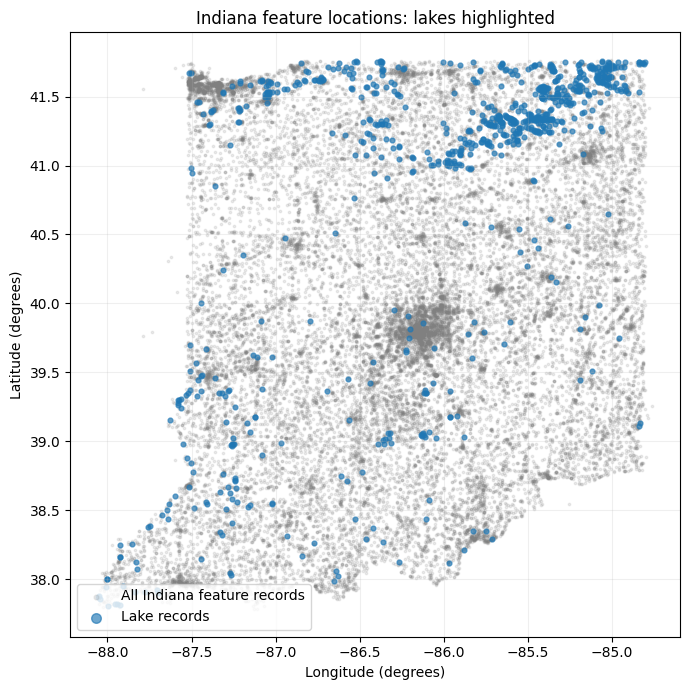

In [41]:
import matplotlib.pyplot as plt

# First remove missing primary coordinates, then exclude zero coordinates.
# Zero is not recognized by isna(), but it is not a valid Indiana location.
locations = indiana.dropna(subset=["PRIM_LAT_DEC", "PRIM_LONG_DEC"])
zero_coordinates = (locations["PRIM_LAT_DEC"] == 0) | (locations["PRIM_LONG_DEC"] == 0)
print("Records excluded from the plot because a primary coordinate is zero:",
      zero_coordinates.sum())
locations = locations[~zero_coordinates]
lake_locations = locations[locations["FEATURE_CLASS"] == "Lake"]

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(locations["PRIM_LONG_DEC"], locations["PRIM_LAT_DEC"],
           s=3, color="gray", alpha=0.15, label="All Indiana feature records")
ax.scatter(lake_locations["PRIM_LONG_DEC"], lake_locations["PRIM_LAT_DEC"],
           s=12, color="tab:blue", alpha=0.65, label="Lake records")
ax.set(title="Indiana feature locations: lakes highlighted",
       xlabel="Longitude (degrees)", ylabel="Latitude (degrees)")
ax.legend(loc="lower left", markerscale=2)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

**My plot notes:** I left out 35 records with zero coordinates because those points are not in Indiana. The lakes seem more concentrated in northern Indiana, especially the northeast. This plot shows locations, not lake sizes.